<a href="https://colab.research.google.com/github/Nnnnueor/TUY_Chamroeun_AI_TP/blob/main/TP4_Optimization_e20230095.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

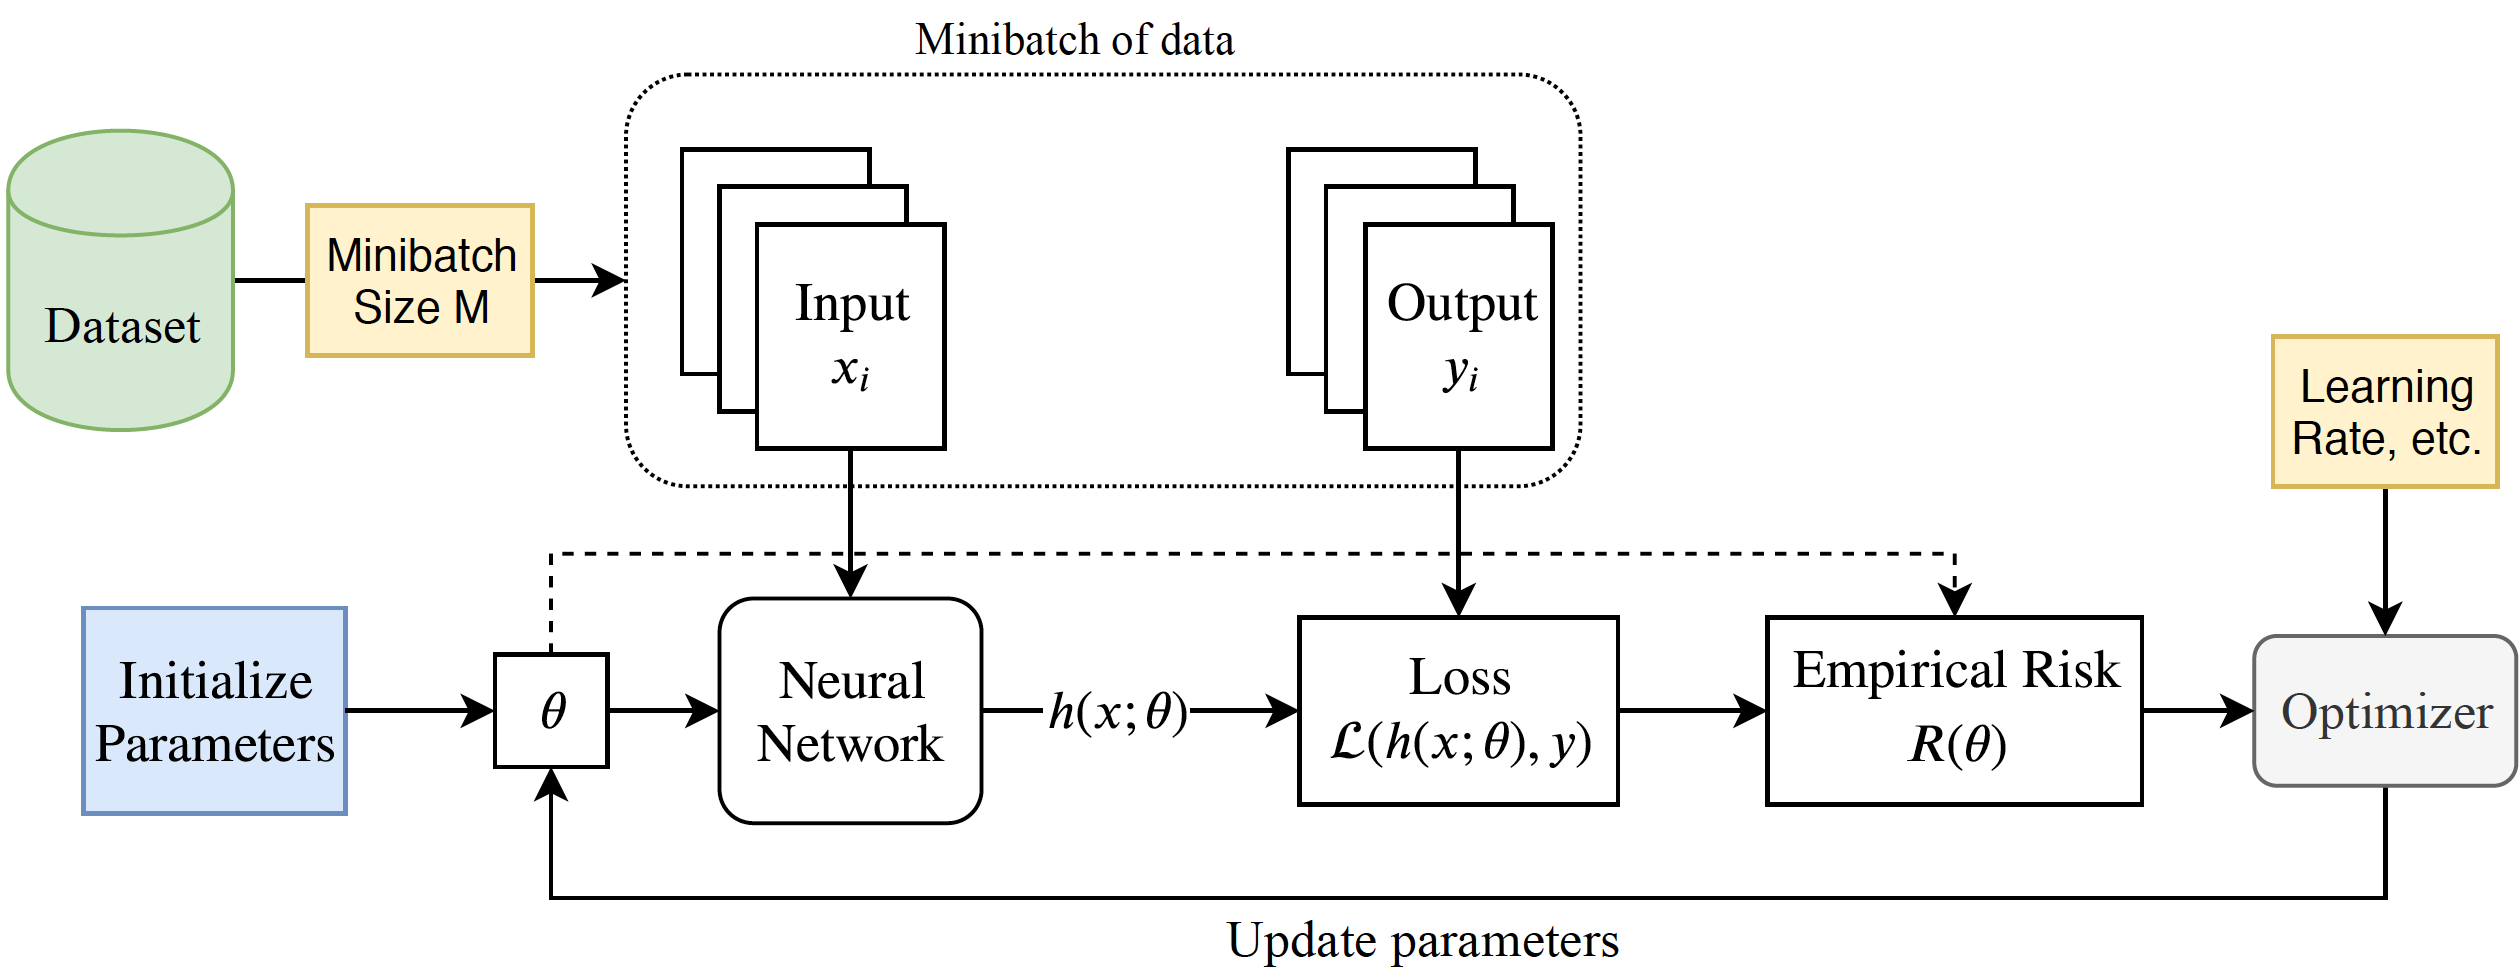

## 0 · Setup

In [ ]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cuda


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


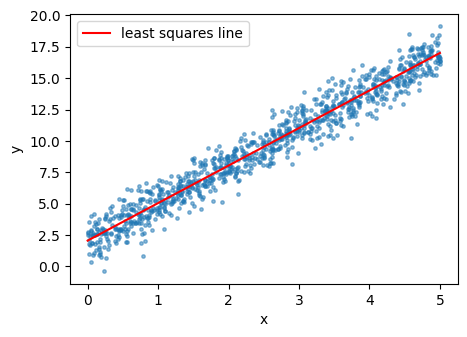

In [ ]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [ ]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 1 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [ ]:
hist_sgd = train_toy(batch_size=1)

epoch  1 | J = 1.0230 | w = 2.891, b = 2.075
epoch  2 | J = 0.9702 | w = 3.026, b = 2.103
epoch  3 | J = 0.9785 | w = 3.060, b = 2.020
epoch  4 | J = 1.0928 | w = 3.165, b = 1.898
epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch  6 | J = 0.9735 | w = 3.021, b = 2.131
epoch  7 | J = 1.0184 | w = 2.892, b = 2.084
epoch  8 | J = 0.9566 | w = 3.013, b = 2.081
epoch  9 | J = 1.0841 | w = 2.855, b = 2.087
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 11 | J = 1.0366 | w = 3.056, b = 2.174
epoch 12 | J = 1.0330 | w = 3.068, b = 2.130
epoch 13 | J = 1.0759 | w = 3.090, b = 2.132
epoch 14 | J = 1.0242 | w = 2.915, b = 1.997
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 16 | J = 1.3911 | w = 2.786, b = 1.976
epoch 17 | J = 1.0375 | w = 2.872, b = 2.112
epoch 18 | J = 0.9864 | w = 3.090, b = 1.933
epoch 19 | J = 0.9582 | w = 3.017, b = 2.076
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 9.16 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [ ]:
hist_mb = train_toy(batch_size=32)

epoch  1 | J = 8.3765 | w = 1.290, b = 7.434
epoch  2 | J = 6.4393 | w = 1.595, b = 6.707
epoch  3 | J = 4.9947 | w = 1.744, b = 6.033
epoch  4 | J = 3.9405 | w = 1.904, b = 5.466
epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch  6 | J = 2.5936 | w = 2.240, b = 4.604
epoch  7 | J = 2.1565 | w = 2.310, b = 4.232
epoch  8 | J = 1.8781 | w = 2.474, b = 3.953
epoch  9 | J = 1.6184 | w = 2.477, b = 3.674
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 11 | J = 1.3177 | w = 2.637, b = 3.265
epoch 12 | J = 1.2207 | w = 2.670, b = 3.093
epoch 13 | J = 1.1542 | w = 2.734, b = 2.958
epoch 14 | J = 1.1020 | w = 2.739, b = 2.826
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 16 | J = 1.0336 | w = 2.810, b = 2.636
epoch 17 | J = 1.0126 | w = 2.829, b = 2.556
epoch 18 | J = 0.9964 | w = 2.867, b = 2.491
epoch 19 | J = 0.9886 | w = 2.900, b = 2.435
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.27 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [ ]:
hist_mom = train_toy(batch_size=64, momentum=0.9)

epoch  1 | J = 6.1264 | w = 1.434, b = 5.922
epoch  2 | J = 1.4561 | w = 2.634, b = 3.438
epoch  3 | J = 1.0152 | w = 3.024, b = 2.225
epoch  4 | J = 0.9865 | w = 3.092, b = 1.923
epoch  5 | J = 0.9673 | w = 3.071, b = 1.918
epoch  6 | J = 0.9700 | w = 3.055, b = 2.005
epoch  7 | J = 0.9650 | w = 3.032, b = 2.063
epoch  8 | J = 1.0744 | w = 3.099, b = 2.102
epoch  9 | J = 0.9555 | w = 3.013, b = 2.073
epoch 10 | J = 0.9531 | w = 2.964, b = 2.075
epoch 11 | J = 0.9698 | w = 2.941, b = 2.056
epoch 12 | J = 0.9842 | w = 2.928, b = 2.052
epoch 13 | J = 0.9596 | w = 2.954, b = 2.062
epoch 14 | J = 0.9543 | w = 3.008, b = 2.081
epoch 15 | J = 0.9756 | w = 3.041, b = 2.074
epoch 16 | J = 0.9545 | w = 3.009, b = 2.079
epoch 17 | J = 0.9496 | w = 2.985, b = 2.056
epoch 18 | J = 0.9775 | w = 3.036, b = 2.098
epoch 19 | J = 0.9519 | w = 3.004, b = 2.070
epoch 20 | J = 0.9505 | w = 3.005, b = 2.048
updates: 320 | training time: 0.16 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

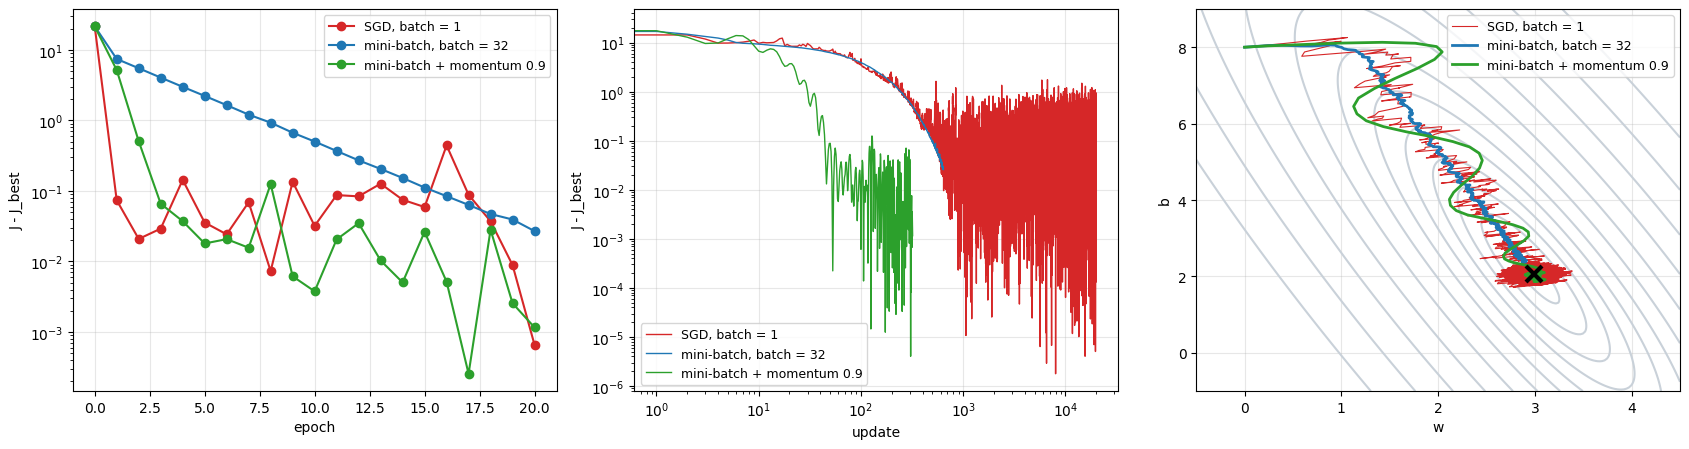

SGD, batch = 1               updates:  20000 | time: 9.16 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.27 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    320 | time: 0.16 s | final J - J_best: 0.0012


In [ ]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.60MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.40MB/s]


train (54000, 784) | val (6000, 784) | test (10000, 784)


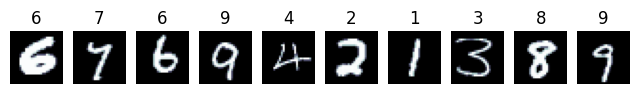

In [ ]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [ ]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.2743 | val loss 0.1614 | val acc 95.08% | 2.5 s
epoch  2 | lr 1.00e-03 | train loss 0.1180 | val loss 0.1251 | val acc 96.15% | 4.4 s
epoch  3 | lr 1.00e-03 | train loss 0.0840 | val loss 0.0955 | val acc 97.03% | 6.3 s
epoch  4 | lr 1.00e-03 | train loss 0.0620 | val loss 0.0803 | val acc 97.40% | 8.5 s
epoch  5 | lr 1.00e-03 | train loss 0.0510 | val loss 0.0833 | val acc 97.43% | 10.5 s
epoch  6 | lr 1.00e-03 | train loss 0.0412 | val loss 0.0867 | val acc 97.52% | 12.4 s
epoch  7 | lr 1.00e-03 | train loss 0.0351 | val loss 0.0944 | val acc 97.22% | 14.3 s
epoch  8 | lr 1.00e-03 | train loss 0.0310 | val loss 0.1220 | val acc 96.82% | 16.1 s
epoch  9 | lr 1.00e-03 | train loss 0.0274 | val loss 0.0923 | val acc 97.78% | 18.0 s
epoch 10 | lr 1.00e-03 | train loss 0.0229 | val loss 0.1100 | val acc 97.40% | 20.0 s


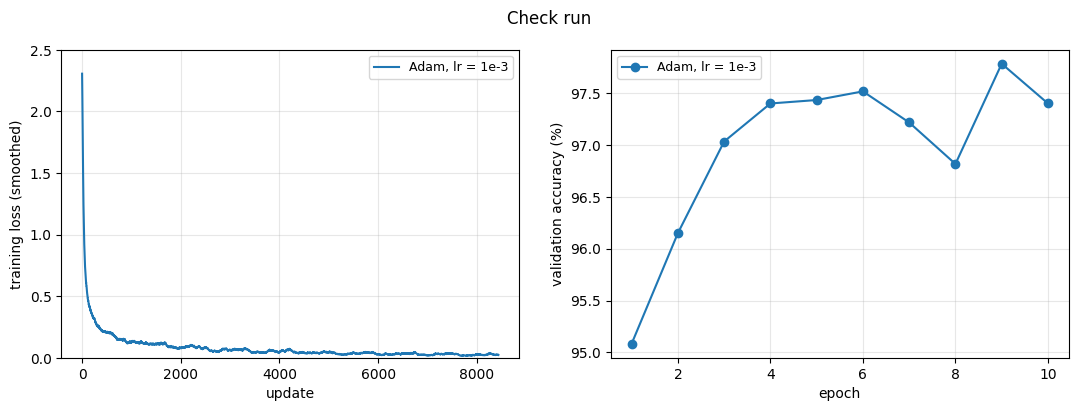

In [ ]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 0.3066 | val loss 0.1598 | val acc 95.05% | 1.7 s
epoch  2 | lr 1.00e-01 | train loss 0.1169 | val loss 0.1095 | val acc 96.67% | 3.4 s
epoch  3 | lr 1.00e-01 | train loss 0.0820 | val loss 0.0984 | val acc 96.95% | 5.2 s
epoch  4 | lr 1.00e-01 | train loss 0.0594 | val loss 0.0945 | val acc 96.97% | 6.7 s
epoch  5 | lr 1.00e-01 | train loss 0.0465 | val loss 0.0845 | val acc 97.30% | 8.2 s
epoch  6 | lr 1.00e-01 | train loss 0.0357 | val loss 0.0929 | val acc 97.45% | 9.7 s
epoch  7 | lr 1.00e-01 | train loss 0.0273 | val loss 0.0848 | val acc 97.53% | 11.2 s
epoch  8 | lr 1.00e-01 | train loss 0.0220 | val loss 0.0878 | val acc 97.62% | 12.7 s
epoch  9 | lr 1.00e-01 | train loss 0.0166 | val loss 0.0936 | val acc 97.52% | 14.2 s
epoch 10 | lr 1.00e-01 | train loss 0.0114 | val loss 0.0804 | val acc 97.60% | 15.8 s


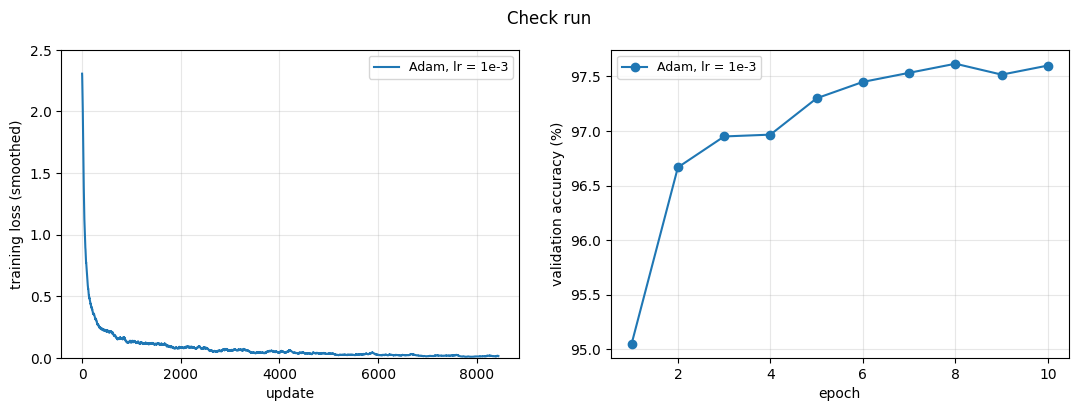

In [ ]:
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 262.4336 | val loss 2.3613 | val acc 12.52% | 2.2 s
epoch  2 | lr 1.00e-01 | train loss 4.0392 | val loss 2.6357 | val acc 9.67% | 4.0 s
epoch  3 | lr 1.00e-01 | train loss 3.1509 | val loss 2.3837 | val acc 11.10% | 5.8 s
epoch  4 | lr 1.00e-01 | train loss 2.3282 | val loss 2.3652 | val acc 9.62% | 7.6 s
epoch  5 | lr 1.00e-01 | train loss 2.3118 | val loss 2.3656 | val acc 9.58% | 9.5 s
epoch  6 | lr 1.00e-01 | train loss 2.3109 | val loss 2.3592 | val acc 11.10% | 11.4 s
epoch  7 | lr 1.00e-01 | train loss 2.3110 | val loss 2.3650 | val acc 11.10% | 13.5 s
epoch  8 | lr 1.00e-01 | train loss 2.3115 | val loss 2.3591 | val acc 9.70% | 15.5 s
epoch  9 | lr 1.00e-01 | train loss 2.3113 | val loss 2.3578 | val acc 10.37% | 17.5 s
epoch 10 | lr 1.00e-01 | train loss 2.3112 | val loss 2.3616 | val acc 9.95% | 19.5 s


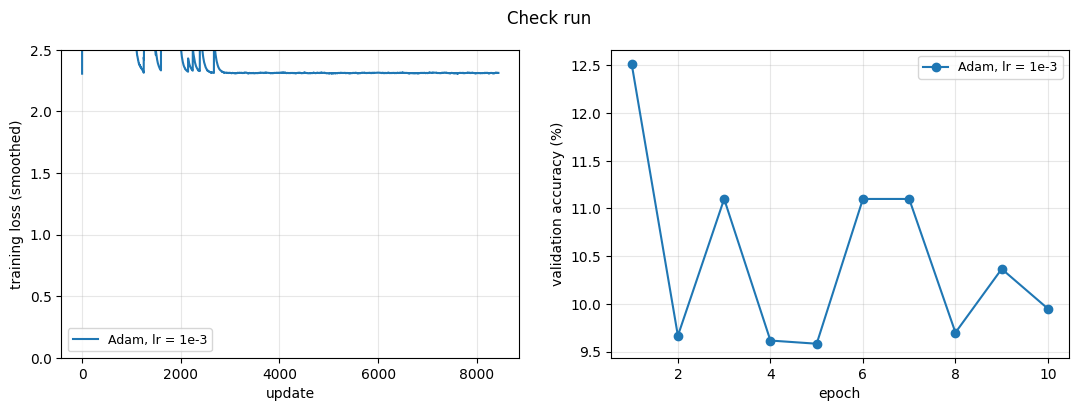

In [ ]:
model = make_model(seed=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.

epoch  1 | lr 1.00e+00 | train loss 2.5133 | val loss 1.5974 | val acc 41.28% | 0.4 s
epoch  2 | lr 1.00e+00 | train loss 1.9113 | val loss 1.9293 | val acc 26.33% | 0.7 s
epoch  3 | lr 1.00e+00 | train loss 1.8403 | val loss 1.8354 | val acc 28.73% | 1.0 s
epoch  4 | lr 1.00e+00 | train loss 1.8480 | val loss 2.1606 | val acc 18.00% | 1.3 s
epoch  5 | lr 1.00e+00 | train loss 2.0679 | val loss 2.0615 | val acc 18.92% | 1.6 s
epoch  1 | lr 3.00e-01 | train loss 0.6940 | val loss 0.3263 | val acc 90.67% | 0.3 s
epoch  2 | lr 3.00e-01 | train loss 0.2314 | val loss 0.3524 | val acc 89.68% | 0.6 s
epoch  3 | lr 3.00e-01 | train loss 0.1474 | val loss 0.2704 | val acc 92.18% | 0.9 s
epoch  4 | lr 3.00e-01 | train loss 0.1072 | val loss 1.6728 | val acc 77.85% | 1.2 s
epoch  5 | lr 3.00e-01 | train loss 0.1064 | val loss 0.2282 | val acc 93.27% | 1.5 s
epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 0.3 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 

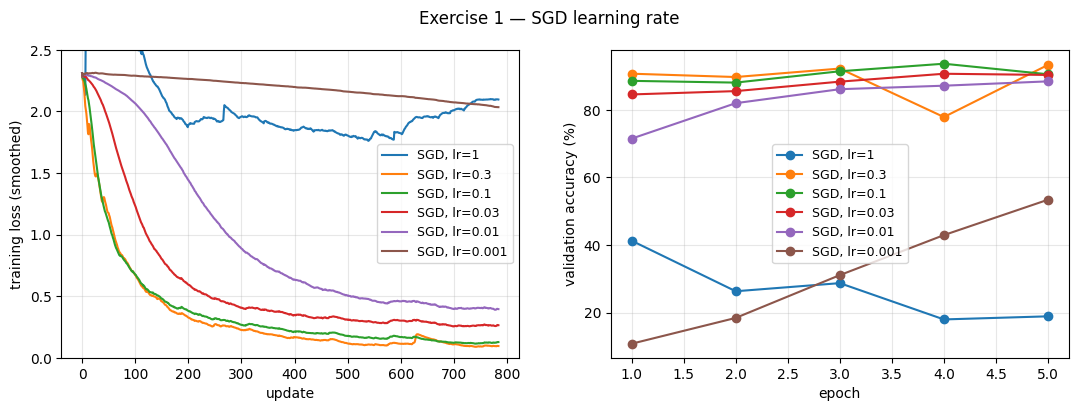


Best validation accuracy
SGD, lr=1         : 41.28%
SGD, lr=0.3       : 93.27%
SGD, lr=0.1       : 93.62%
SGD, lr=0.03      : 90.65%
SGD, lr=0.01      : 88.40%
SGD, lr=0.001     : 53.40%


In [ ]:
lr_values = [1, 0.3, 0.1, 0.03, 0.01, 0.001]
ex1_histories = {}

for lr in lr_values:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr)
    history = fit(model, optimizer,
                   make_loader(batch_size=64, n_train=10_000, seed=0),
                   epochs=5)
    ex1_histories[f"SGD, lr={lr:g}"] = history

plot_history(ex1_histories, "Exercise 1 — SGD learning rate")
print("\nBest validation accuracy")
for label, history in ex1_histories.items():
    best = max(history["val_acc"])
    print(f"{label:18s}: {best:.2f}%"
          f"{' (diverged)' if history['diverged'] else ''}")

**Exercise 1: your observations and explanation.**

- A learning rate that is too large can make the upadates unstable or cause the loss to diverge.
- A very small learning rate is usually stable, but learns slowly within only five epochs.
- The most useful learning rate is the one with the highest validation accuracy while keepiing the loss stable.
- The printed best validation accuracies and the plot above show which learning rate works best for this model.

In our experiment, a learning rate of **0.1** achieved the highest validation accuracy of **93.62%**, while a learning rate of **1.0** performed poorly because the upadates were too large.

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


Learning rate = 0.01
epoch  1 | lr 1.00e-02 | train loss 0.4416 | val loss 0.4109 | val acc 89.62% | 14.2 s
epoch  2 | lr 1.00e-02 | train loss 0.2115 | val loss 0.2225 | val acc 93.57% | 28.4 s
epoch  3 | lr 1.00e-02 | train loss 0.1406 | val loss 0.2452 | val acc 93.20% | 42.6 s
batch=1      | upadtes/epoch=10000 | mean time/epoch=14.19 s | best val acc=93.57%


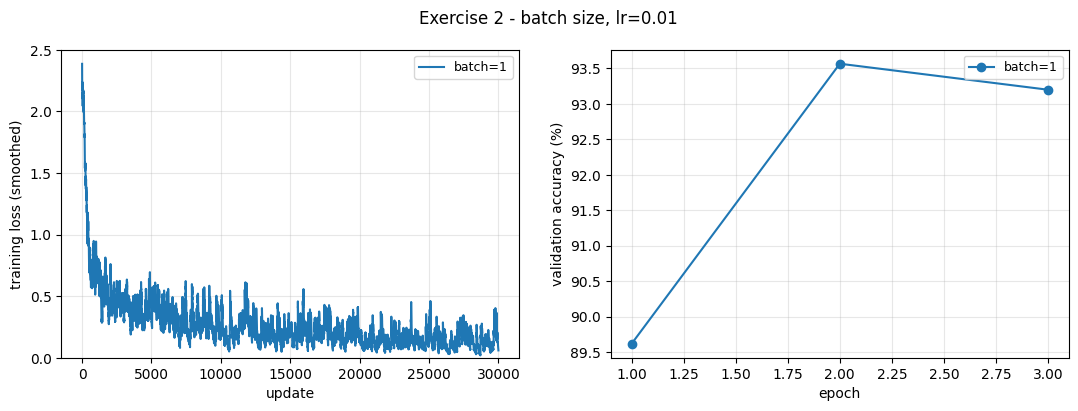

epoch  1 | lr 1.00e-02 | train loss 1.4694 | val loss 0.6934 | val acc 83.52% | 0.5 s
epoch  2 | lr 1.00e-02 | train loss 0.5182 | val loss 0.4488 | val acc 86.75% | 1.1 s
epoch  3 | lr 1.00e-02 | train loss 0.3849 | val loss 0.3840 | val acc 88.87% | 1.6 s
batch=32     | upadtes/epoch=  313 | mean time/epoch=0.53 s | best val acc=88.87%


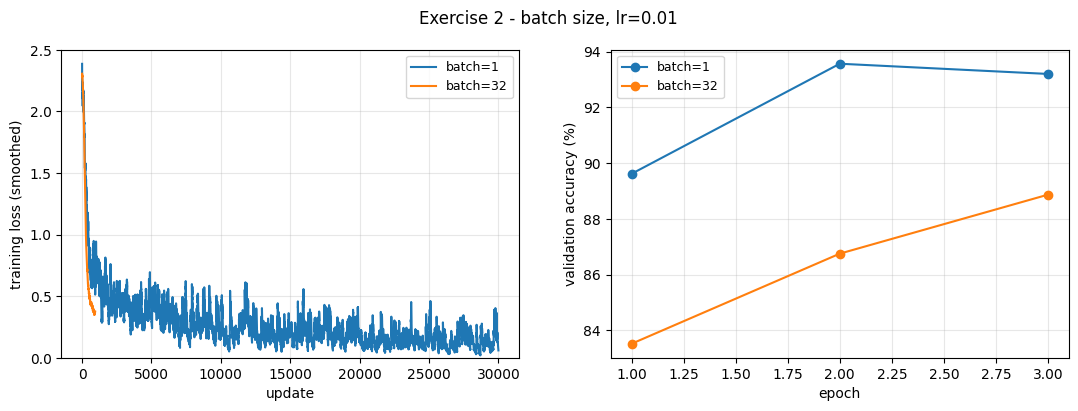

epoch  1 | lr 1.00e-02 | train loss 2.2508 | val loss 2.1822 | val acc 25.18% | 0.1 s
epoch  2 | lr 1.00e-02 | train loss 2.1034 | val loss 2.0016 | val acc 51.67% | 0.3 s
epoch  3 | lr 1.00e-02 | train loss 1.8804 | val loss 1.7294 | val acc 64.63% | 0.4 s
batch=256    | upadtes/epoch=   40 | mean time/epoch=0.13 s | best val acc=64.63%


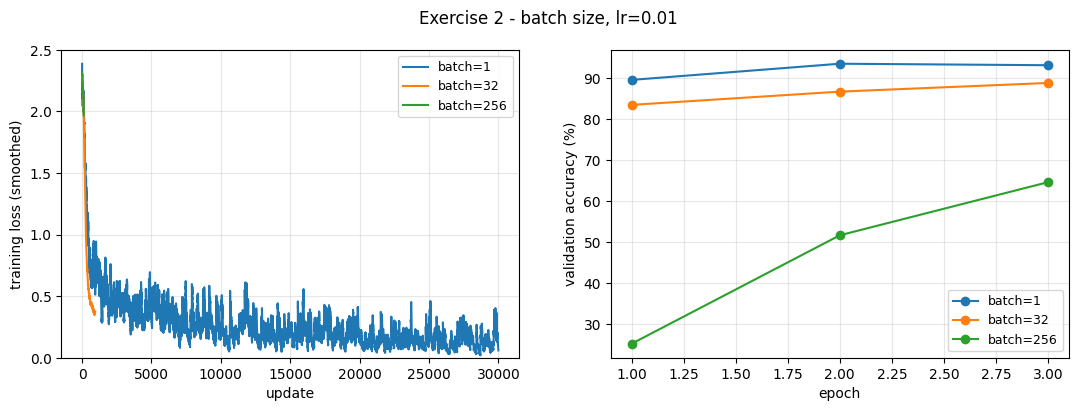

epoch  1 | lr 1.00e-02 | train loss 2.3101 | val loss 2.3070 | val acc 9.77% | 0.2 s
epoch  2 | lr 1.00e-02 | train loss 2.3068 | val loss 2.3038 | val acc 9.80% | 0.3 s
epoch  3 | lr 1.00e-02 | train loss 2.3036 | val loss 2.3006 | val acc 9.78% | 0.4 s
batch=10000  | upadtes/epoch=    1 | mean time/epoch=0.14 s | best val acc=9.80%


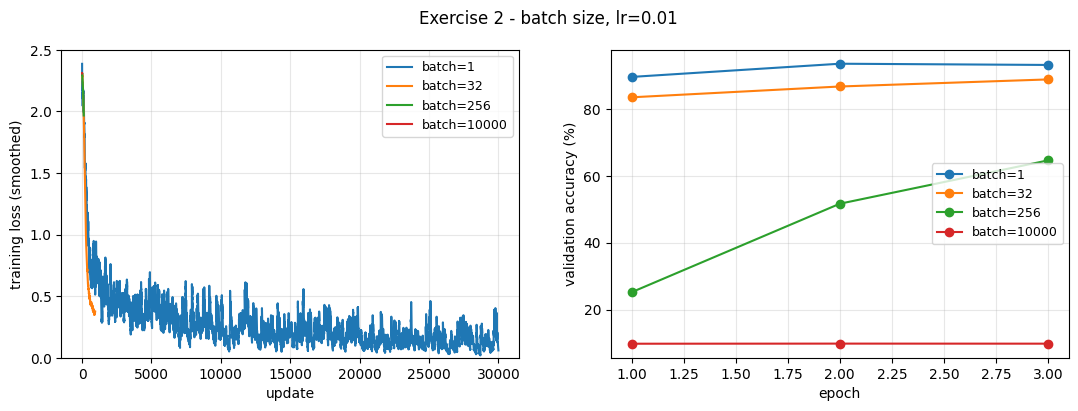


Learning rate = 0.1
epoch  1 | lr 1.00e-01 | train loss 3.3113 | val loss 2.4680 | val acc 9.95% | 14.4 s
epoch  2 | lr 1.00e-01 | train loss nan | val loss nan | val acc 9.72% | 27.6 s
diverged (loss is nan or inf): stopping
batch=1      | upadtes/epoch=10000 | mean time/epoch=13.82 s | best val acc=9.95% | DIERGE


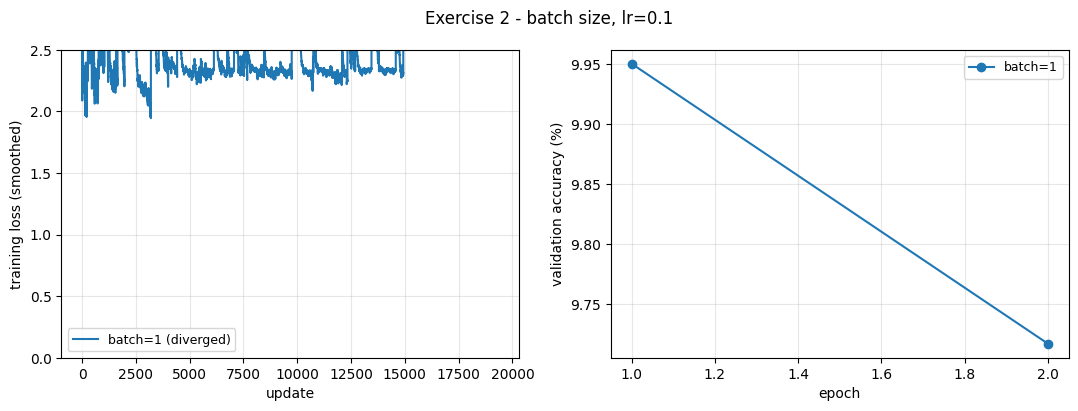

epoch  1 | lr 1.00e-01 | train loss 0.5535 | val loss 0.3337 | val acc 89.72% | 0.6 s
epoch  2 | lr 1.00e-01 | train loss 0.2262 | val loss 0.2587 | val acc 91.73% | 1.1 s
epoch  3 | lr 1.00e-01 | train loss 0.1440 | val loss 0.2135 | val acc 93.57% | 1.7 s
batch=32     | upadtes/epoch=  313 | mean time/epoch=0.56 s | best val acc=93.57%


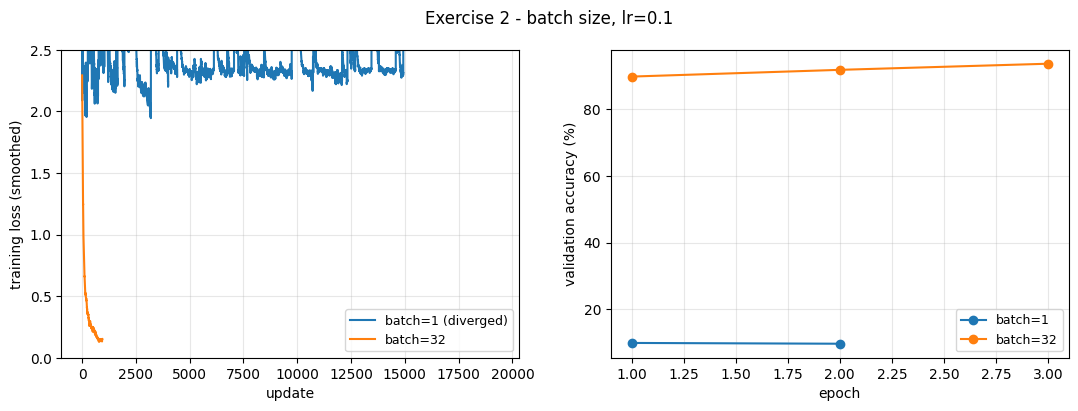

epoch  1 | lr 1.00e-01 | train loss 1.3641 | val loss 0.8300 | val acc 72.13% | 0.1 s
epoch  2 | lr 1.00e-01 | train loss 0.5005 | val loss 0.9598 | val acc 67.43% | 0.3 s
epoch  3 | lr 1.00e-01 | train loss 0.3926 | val loss 0.7778 | val acc 74.63% | 0.4 s
batch=256    | upadtes/epoch=   40 | mean time/epoch=0.13 s | best val acc=74.63%


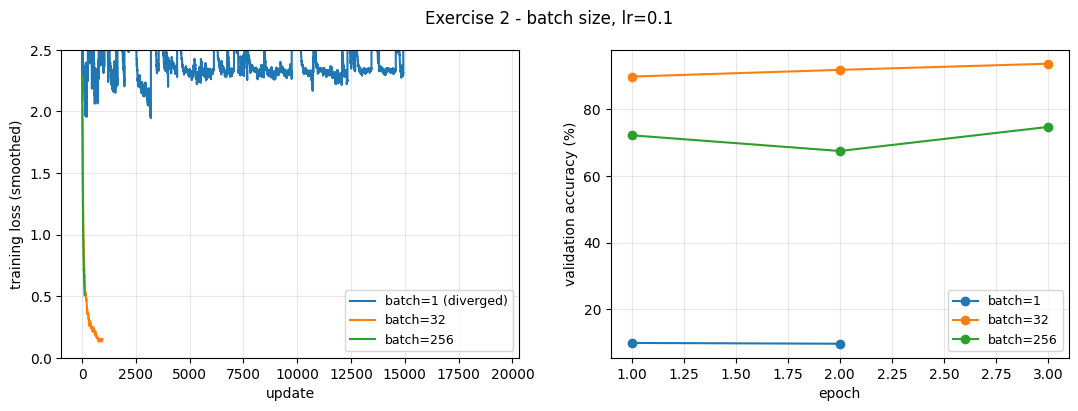

epoch  1 | lr 1.00e-01 | train loss 2.3101 | val loss 2.2786 | val acc 10.00% | 0.1 s
epoch  2 | lr 1.00e-01 | train loss 2.2784 | val loss 2.2488 | val acc 12.08% | 0.2 s
epoch  3 | lr 1.00e-01 | train loss 2.2485 | val loss 2.2186 | val acc 17.55% | 0.5 s
batch=10000  | upadtes/epoch=    1 | mean time/epoch=0.16 s | best val acc=17.55%


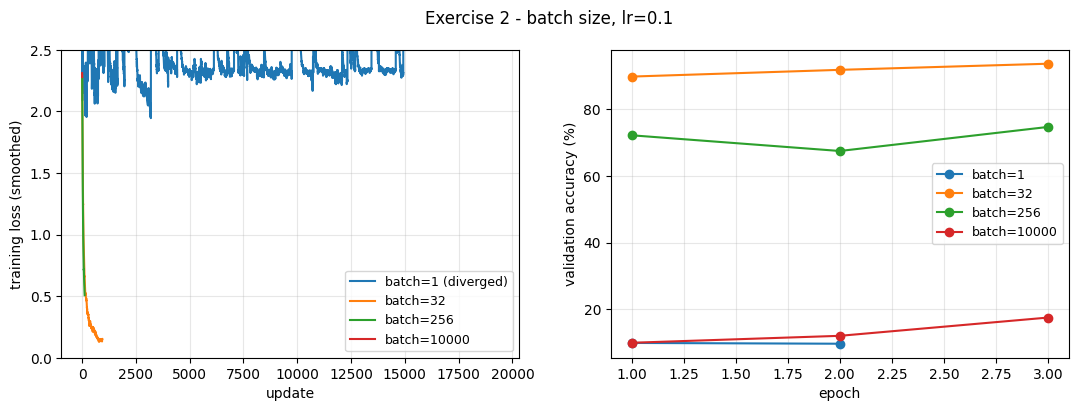

In [ ]:
# Exercise 2: Batch sizes 1, 32, 256 and 10000, at two learning rates
batch_sizes = [1, 32, 256, 10_000]
ex2_histories = {}

for lr in [0.01, 0.1]:
  current = {}
  print(f"\nLearning rate = {lr:g}")
  for batch_size in batch_sizes:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr)
    loader = make_loader(batch_size=batch_size, n_train=10_000, seed=0)
    history = fit(model, optimizer, loader, epochs=3)
    label = f"batch={batch_size}"
    current[label] = history
    epoch_times = np.diff([0.0] + history["time"])
    updates_per_epoch = len(loader)
    mean_time = float(np.mean(epoch_times)) if len(epoch_times) else float("nan")
    print(f"{label:12s} | upadtes/epoch={updates_per_epoch:5d} | "
          f"mean time/epoch={mean_time:.2f} s | "
          f"best val acc={max(history['val_acc']):.2f}%"
          f"{' | DIERGE' if history['diverged'] else ''}")
    ex2_histories[lr] = current
    plot_history(current, f"Exercise 2 - batch size, lr={lr:g}")


**Exercise 2: your observations and explanation.**

- Batch size 1 makes many updates per epoch, but each update is noisy and the run is relatively slow.
- Large batches make fewer upates per epoch and usually give smoother gradient estimates.
- A full-batches update uses all 10,000 examples once per epoch, so it makes only one update per epoch.
- The best choice balences validation accuracy, stability, and computation time. A larger learning rate may help some batch sizes but can also make training unstable.

In our experiment, batch size 1 required 10,000 updates per epoch, while batch size 10,000 required only one update. Therefore, mini-batch training provides a practical balance between computional efficiency and gradient stability.

### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 0.6 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 0.9 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 1.2 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 1.6 s
epoch  1 | lr 1.00e-02 | train loss 0.8135 | val loss 0.3554 | val acc 89.23% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.2945 | val loss 0.2834 | val acc 91.58% | 0.6 s
epoch  3 | lr 1.00e-02 | train loss 0.2109 | val loss 0.2458 | val acc 92.42% | 0.9 s
epoch  4 | lr 1.00e-02 | train loss 0.1593 | val loss 0.2065 | val acc 93.95% | 1.3 s
epoch  5 | lr 1.00e-02 | train loss 0.1195 | val loss 0.2028 | val acc 93.93% | 1.6 s
epoch  1 | lr 1.00e-02 | train loss 0.7820 | val loss 0.3632 | val acc 88.67% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.2885 | val loss 

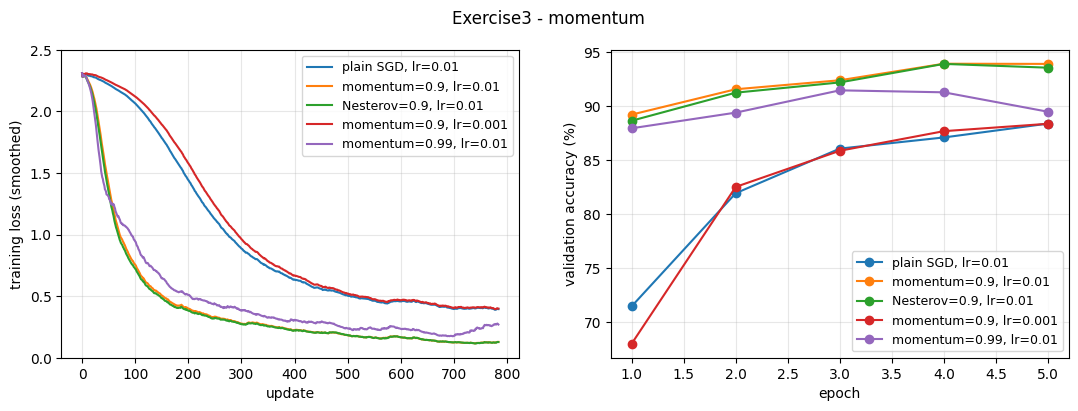


Best validation accuracy
plain SGD, lr=0.01            : 88.40%
momentum=0.9, lr=0.01         : 93.95%
Nesterov=0.9, lr=0.01         : 93.93%
momentum=0.9, lr=0.001        : 88.38%
momentum=0.99, lr=0.01        : 91.48%


In [ ]:
# Exercise 3: momentumm and Nesterov momentum.
ex3_configs = [
    ("plain SGD, lr=0.01", 0.01, 0.0, False),
    ("momentum=0.9, lr=0.01", 0.01, 0.9, False),
    ("Nesterov=0.9, lr=0.01", 0.01, 0.9, True),
    ("momentum=0.9, lr=0.001", 0.001, 0.9, False),
    ("momentum=0.99, lr=0.01", 0.01, 0.99, False)
]
ex3_histories ={}

for label, lr, momentum, nesterov in ex3_configs:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum, nesterov=nesterov)
    history = fit(model, optimizer, make_loader(batch_size=64, n_train=10_000, seed=0), epochs=5)
    ex3_histories[label] = history

plot_history(ex3_histories, "Exercise3 - momentum")
print("\nBest validation accuracy")
for label, history in ex3_histories.items():
  print(f"{label:30s}: {max(history['val_acc']):.2f}%"
        f"{' (diverge)' if history['diverged'] else ''}")

**Exercise 3: your observations and explanation.**

- Momentum uses information from previous gradients, which can accelerate progress and reduce zig-zagging.
- Nesterov momentum calculates the gradient after a small look-ahead step and may improve the update.
- A smaller learning rate with momentum can ve more stable but may learn more slowly.
- Very high momentum (0.99) can be harder to control. Compare the validation curve and divergence massages to decides to decide which setting worked best.

Momentum with a value of 0.9 achieved the highest validation accuracy of **93.95%**, slightly outperforming Nesterov momentum. Increasing momentum to 0.99 did not improve the result.

### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

SGD            lr=1e-01 | best val acc=93.62%
SGD            lr=1e-02 | best val acc=88.40%
SGD            lr=1e-03 | best val acc=53.40%
SGD            lr=1e-04 | best val acc=9.88%
SGD momentum   lr=1e-01 | best val acc=92.75%
SGD momentum   lr=1e-02 | best val acc=93.95%
SGD momentum   lr=1e-03 | best val acc=88.38%
SGD momentum   lr=1e-04 | best val acc=52.55%
Adagrad        lr=1e-01 | best val acc=92.35%
Adagrad        lr=1e-02 | best val acc=93.93%
Adagrad        lr=1e-03 | best val acc=89.15%
Adagrad        lr=1e-04 | best val acc=67.98%
RMSprop        lr=1e-01 | best val acc=22.07%
RMSprop        lr=1e-02 | best val acc=90.07%
RMSprop        lr=1e-03 | best val acc=94.18%
RMSprop        lr=1e-04 | best val acc=89.92%
Adam           lr=1e-01 | best val acc=27.10%
Adam           lr=1e-02 | best val acc=92.45%
Adam           lr=1e-03 | best val acc=94.17%
Adam           lr=1e-04 | best val acc=90.03%
AdamW          lr=1e-01 | best val acc=36.60%
AdamW          lr=1e-02 | best val 

,1e-01,1e-02,1e-03,1e-04
SGD,93.62,88.40,53.40,9.88
SGD momentum,92.75,93.95,88.38,52.55
Adagrad,92.35,93.93,89.15,67.98
RMSprop,22.07,90.07,94.18,89.92
Adam,27.10,92.45,94.17,90.03
AdamW,36.60,92.78,94.02,90.05


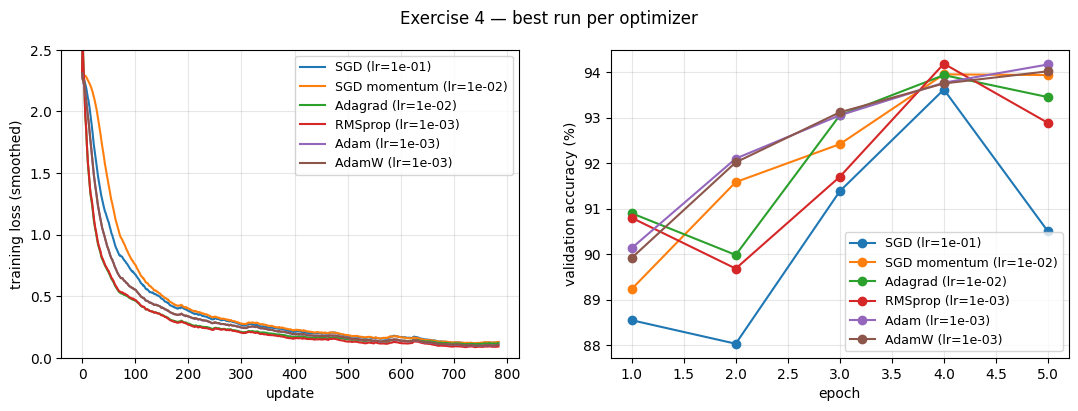

In [ ]:
# Exercise 4: compare optimizers and learning rates.
learning_rates = [1e-1, 1e-2, 1e-3, 1e-4]
optimizer_names = ["SGD", "SGD momentum", "Adagrad", "RMSprop", "Adam", "AdamW"]
ex4_scores = {name: {} for name in optimizer_names}
ex4_histories = {}

def build_optimizer(name, parameters, lr):
    if name == "SGD":
        return optim.SGD(parameters, lr=lr)
    if name == "SGD momentum":
        return optim.SGD(parameters, lr=lr, momentum=0.9)
    if name == "Adagrad":
        return optim.Adagrad(parameters, lr=lr)
    if name == "RMSprop":
        return optim.RMSprop(parameters, lr=lr)
    if name == "Adam":
        return optim.Adam(parameters, lr=lr)
    if name == "AdamW":
        return optim.AdamW(parameters, lr=lr)
    raise ValueError(f"Unknown optimizer: {name}")

for name in optimizer_names:
    for lr in learning_rates:
        model = make_model(seed=0)
        optimizer = build_optimizer(name, model.parameters(), lr)
        history = fit(model, optimizer,
                      make_loader(batch_size=64, n_train=10_000, seed=0),
                      epochs=5, verbose=False)
        ex4_scores[name][lr] = max(history["val_acc"])
        ex4_histories[(name, lr)] = history
        print(f"{name:14s} lr={lr:.0e} | best val acc={max(history['val_acc']):.2f}%"
              f"{' | DIVERGED' if history['diverged'] else ''}")

# Display the requested comparison table.
try:
    import pandas as pd
    ex4_table = pd.DataFrame(ex4_scores).T
    ex4_table.columns = [f"{lr:.0e}" for lr in learning_rates]
    display(ex4_table.round(2))
except ImportError:
    for name in optimizer_names:
        print(name, [round(ex4_scores[name][lr], 2) for lr in learning_rates])

# Plot the best learning-rate run for each optimizer.
ex4_best_histories = {}
for name in optimizer_names:
    best_lr = max(learning_rates, key=lambda lr: ex4_scores[name][lr])
    ex4_best_histories[f"{name} (lr={best_lr:.0e})"] = ex4_histories[(name, best_lr)]
plot_history(ex4_best_histories, "Exercise 4 — best run per optimizer")

**Exercise 4: your observations and explanation.** :

- The optimizers adapt parameters in different ways, so they do not necessarily prefer the same learning rate.
- Plain SGD is sensitive to the learning rate. Momentum can speed up SGD, while Adagrad, RMSprop, Adam, and AdamW adapt their effective step size.
- Compare the table to identify the best learning rate for each optimizer.
- The final plot compares the best validation run for each optimizer. A high score is useful only when training is stable and does not diverge.

From our experiments, RMSprop achieved the highest validation accuracy of **94.18%** with a learning rate of 0.001. This show that optimizer performance depends on selecting an appropriate learning rate.

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

epoch  1 | lr 5.00e-02 | train loss 0.5625 | val loss 0.3042 | val acc 91.05% | 0.3 s
epoch  2 | lr 5.00e-02 | train loss 0.2181 | val loss 0.2179 | val acc 93.78% | 0.7 s
epoch  3 | lr 5.00e-02 | train loss 0.1439 | val loss 0.2658 | val acc 92.87% | 1.0 s
epoch  4 | lr 5.00e-02 | train loss 0.1015 | val loss 0.2016 | val acc 94.43% | 1.3 s
epoch  5 | lr 5.00e-02 | train loss 0.0624 | val loss 0.2579 | val acc 93.77% | 1.6 s
epoch  6 | lr 5.00e-02 | train loss 0.0709 | val loss 0.1956 | val acc 95.07% | 1.9 s
epoch  7 | lr 5.00e-02 | train loss 0.0409 | val loss 0.2121 | val acc 95.10% | 2.2 s
epoch  8 | lr 5.00e-02 | train loss 0.0159 | val loss 0.2283 | val acc 95.88% | 2.6 s
epoch  9 | lr 5.00e-02 | train loss 0.0255 | val loss 0.2840 | val acc 94.73% | 2.9 s
epoch 10 | lr 5.00e-02 | train loss 0.0446 | val loss 0.3300 | val acc 94.33% | 3.2 s
epoch  1 | lr 5.00e-02 | train loss 0.5625 | val loss 0.3042 | val acc 91.05% | 0.3 s
epoch  2 | lr 5.00e-02 | train loss 0.2181 | val loss 

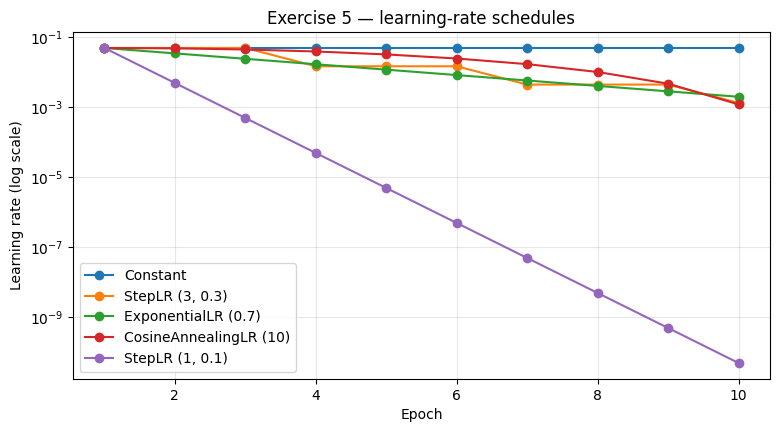

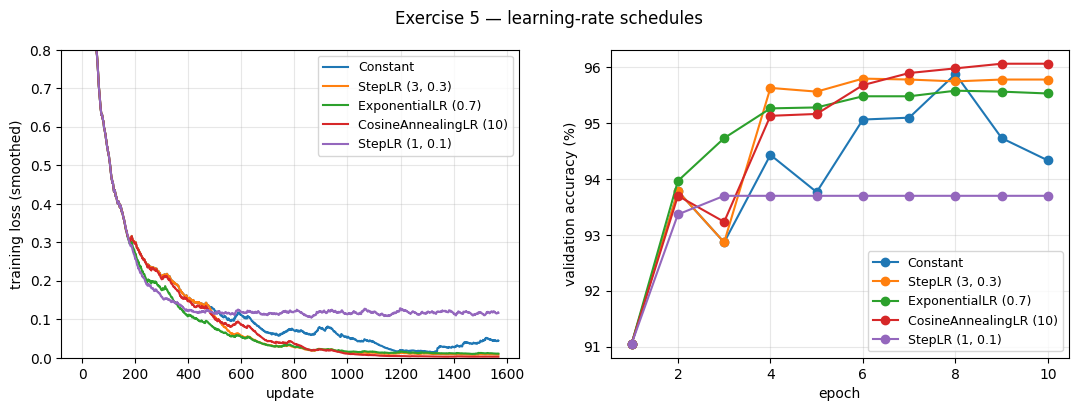


Best validation accuracy
Constant                   : 95.88%
StepLR (3, 0.3)            : 95.80%
ExponentialLR (0.7)        : 95.58%
CosineAnnealingLR (10)     : 96.07%
StepLR (1, 0.1)            : 93.70%


In [ ]:
# Exercise 5: compare constant and scheduled learning rates.
ex5_histories = {}
ex5_lr_curves = {}

schedule_names = ["Constant", "StepLR (3, 0.3)", "ExponentialLR (0.7)",
                  "CosineAnnealingLR (10)", "StepLR (1, 0.1)"]

for name in schedule_names:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    if name == "Constant":
        scheduler = None
    elif name == "StepLR (3, 0.3)":
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)
    elif name == "ExponentialLR (0.7)":
        scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)
    elif name == "CosineAnnealingLR (10)":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
    else:
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)

    history = fit(model, optimizer,
                  make_loader(batch_size=64, n_train=10_000, seed=0),
                  epochs=10, scheduler=scheduler)
    ex5_histories[name] = history
    ex5_lr_curves[name] = history["lr"]

plt.figure(figsize=(9, 4.5))
for name, rates in ex5_lr_curves.items():
    plt.plot(range(1, len(rates) + 1), rates, marker="o", label=name)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Learning rate (log scale)")
plt.title("Exercise 5 — learning-rate schedules")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plot_history(ex5_histories, "Exercise 5 — learning-rate schedules", ylim=(0, 0.8))
print("\nBest validation accuracy")
for name, history in ex5_histories.items():
    print(f"{name:27s}: {max(history['val_acc']):.2f}%")

**Exercise 5: your observations and explanation.**

- A constant learning rate keeps the update size unchaged throughout training.
- StepLR reduces the learning rate fixed intervals; ExponentialLR reduces it gradually every epoch.
- CosinAnnealingLR decreases the learning rate smoothly toward zero.
- Decaying too early can make learning slow before the model has learned enough. The plot show how each schedule affects training and validation accuracy.

CosnAnnealingLR achieved the highest validation accuracy of **96.07%**, while reducing the learning rate too early limited the model's learning progress.

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

epoch  1 | lr 1.00e+00 | train loss 895366979517070848.0000 | val loss 2772487800553330688.0000 | val acc 9.52% | 0.3 s
epoch  2 | lr 1.00e+00 | train loss nan | val loss nan | val acc 9.72% | 0.3 s
diverged (loss is nan or inf): stopping
epoch  1 | lr 1.00e+00 | train loss 0.7521 | val loss 0.5730 | val acc 85.48% | 0.5 s
epoch  2 | lr 1.00e+00 | train loss 0.5754 | val loss 0.5755 | val acc 87.73% | 0.9 s
epoch  3 | lr 1.00e+00 | train loss 0.5713 | val loss 0.5105 | val acc 88.93% | 1.3 s
epoch  4 | lr 1.00e+00 | train loss 0.6190 | val loss 0.8131 | val acc 81.78% | 1.8 s
epoch  5 | lr 1.00e+00 | train loss 0.5589 | val loss 0.6402 | val acc 89.70% | 2.2 s
epoch  1 | lr 1.00e-01 | train loss 0.6215 | val loss 0.4023 | val acc 89.68% | 0.4 s
epoch  2 | lr 1.00e-01 | train loss 0.3069 | val loss 0.2899 | val acc 91.83% | 0.8 s
epoch  3 | lr 1.00e-01 | train loss 0.2350 | val loss 0.2917 | val acc 92.45% | 1.2 s
epoch  4 | lr 1.00e-01 | train loss 0.2067 | val loss 0.3336 | val acc 92

,Without batch norm,With batch norm
Learning rate,,
1.000,9.72,89.70
0.100,92.75,95.15
0.010,93.95,95.38
0.001,88.38,92.75


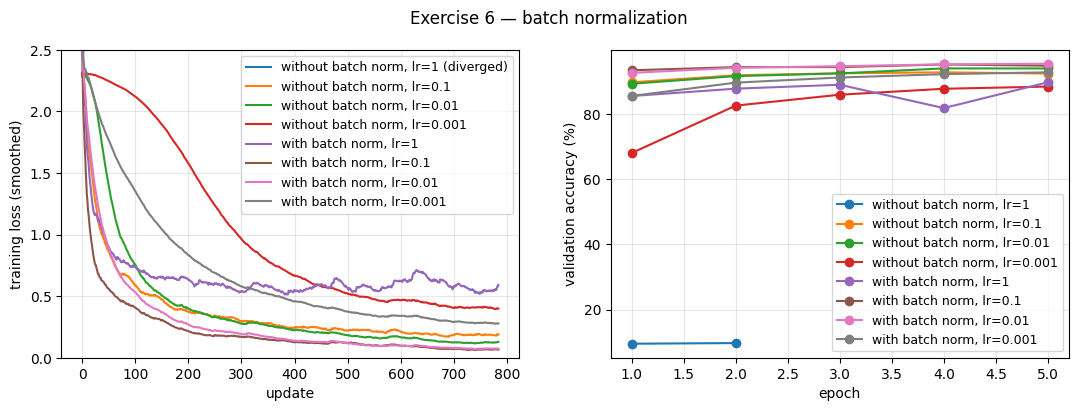

Validation accuracy in eval() mode:  95.38%
Validation accuracy in train() mode, batch size 8: 85.15%
The difference occurs because BatchNorm uses running statistics in eval() mode and each small batch's statistics in train() mode.


In [ ]:
# Exercise 6: compare SGD with and without batch normalization.
ex6_lrs = [1.0, 0.1, 0.01, 0.001]
ex6_histories = {"without batch norm": {}, "with batch norm": {}}
ex6_models = {"without batch norm": {}, "with batch norm": {}}

for lr in ex6_lrs:
    for use_bn in [False, True]:
        label = "with batch norm" if use_bn else "without batch norm"
        model = make_model(seed=0, batch_norm=use_bn)
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        history = fit(model, optimizer,
                      make_loader(batch_size=64, n_train=10_000, seed=0),
                      epochs=5)
        ex6_histories[label][lr] = history
        ex6_models[label][lr] = model

# Table: rows are learning rates, columns are batch norm settings.
try:
    import pandas as pd
    ex6_table = pd.DataFrame({
        "Without batch norm": [max(ex6_histories["without batch norm"][lr]["val_acc"]) for lr in ex6_lrs],
        "With batch norm": [max(ex6_histories["with batch norm"][lr]["val_acc"]) for lr in ex6_lrs],
    }, index=ex6_lrs)
    ex6_table.index.name = "Learning rate"
    display(ex6_table.round(2))
except ImportError:
    print("lr | without BN | with BN")
    for lr in ex6_lrs:
        print(lr, max(ex6_histories["without batch norm"][lr]["val_acc"]),
              max(ex6_histories["with batch norm"][lr]["val_acc"]))

# Plot all eight runs together.
all_ex6 = {}
for label in ex6_histories:
    for lr, history in ex6_histories[label].items():
        all_ex6[f"{label}, lr={lr:g}"] = history
plot_history(all_ex6, "Exercise 6 — batch normalization")

# Compare evaluation mode with train mode using mini-batches of 8.
bn_model = ex6_models["with batch norm"][0.01]
bn_model.eval()
eval_loss, eval_acc = evaluate(bn_model, X_val, y_val)

bn_model.train()
train_mode_correct, train_mode_total = 0, 0
with torch.no_grad():
    for start in range(0, len(X_val), 8):
        xb = X_val[start:start + 8].to(device)
        yb = y_val[start:start + 8].to(device)
        predictions = bn_model(xb).argmax(dim=1)
        train_mode_correct += (predictions == yb).sum().item()
        train_mode_total += len(yb)
train_mode_acc = 100 * train_mode_correct / train_mode_total

print(f"Validation accuracy in eval() mode:  {eval_acc:.2f}%")
print(f"Validation accuracy in train() mode, batch size 8: {train_mode_acc:.2f}%")
print("The difference occurs because BatchNorm uses running statistics in eval() "
      "mode and each small batch's statistics in train() mode.")

**Exercise 6: your observations and explanation.**

- Batch normalization standardizes hidden-layer activations during training and can make optimization more stable.
- It may allow a larger learning rate, although the result depends on the learning rate and data.
- In `eval()` mode, BatchNorm uses running mean and variance collected during training.
- In `train()` mode, it uses statistics from each current mini-batch. With batches of only 8 validation examples, those statistics can be noisy, so the two accuracies may differ.

Batch normalization improved validation accuracy for all four learning rates in our experiment. The largest improvement occurred at a learning rate of 1.0.

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

In [ ]:
# Exercise 7: Choose a strong configuration based on the validation results above.
BEST_CONFIG = {
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 64,
    "batch_norm": True,
    "schedule": "none",
}

best_model = make_model(seed=0, batch_norm=BEST_CONFIG["batch_norm"])
best_optimizer = optim.Adam(best_model.parameters(), lr=BEST_CONFIG["learning_rate"])
best_history = fit(best_model, best_optimizer,
                   make_loader(batch_size=BEST_CONFIG["batch_size"],
                               n_train=None, seed=0),
                   epochs=10)

print("\nChosen configuration and reasons")
print("- Optimizer: Adam  adapts the step size for each parameter.")
print("- Learning rate: 0.001  a commonly stable starting value for Adam.")
print("- Batch size: 64  balances gradient stability and number of updates.")
print("- Batch normalization: enabled  can stabilize hidden-layer activations.")
print("- Schedule: none  keep the learning rate constant for this comparison.")
print("\nValidation accuracy by epoch")
for epoch, accuracy in enumerate(best_history["val_acc"], start=1):
    print(f"Epoch {epoch:2d}: {accuracy:.2f}%")
best_val_accuracy = max(best_history["val_acc"])
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")

epoch  1 | lr 1.00e-03 | train loss 0.2483 | val loss 0.1265 | val acc 96.15% | 2.5 s
epoch  2 | lr 1.00e-03 | train loss 0.0951 | val loss 0.0931 | val acc 97.00% | 4.7 s
epoch  3 | lr 1.00e-03 | train loss 0.0690 | val loss 0.0744 | val acc 97.55% | 6.8 s
epoch  4 | lr 1.00e-03 | train loss 0.0530 | val loss 0.0691 | val acc 97.92% | 9.0 s
epoch  5 | lr 1.00e-03 | train loss 0.0435 | val loss 0.0705 | val acc 97.78% | 11.2 s
epoch  6 | lr 1.00e-03 | train loss 0.0368 | val loss 0.0685 | val acc 97.97% | 13.5 s
epoch  7 | lr 1.00e-03 | train loss 0.0323 | val loss 0.0724 | val acc 97.80% | 15.9 s
epoch  8 | lr 1.00e-03 | train loss 0.0260 | val loss 0.0686 | val acc 98.05% | 18.0 s
epoch  9 | lr 1.00e-03 | train loss 0.0253 | val loss 0.0742 | val acc 97.72% | 20.3 s
epoch 10 | lr 1.00e-03 | train loss 0.0221 | val loss 0.0793 | val acc 97.72% | 22.4 s

Chosen configuration and reasons
- Optimizer: Adam  adapts the step size for each parameter.
- Learning rate: 0.001  a commonly stabl

**Exercise 7: your observations and explanation.**

Selected configuration is Adam with learning rate 0.001, batch size 64, batch normalization, and no learning-rate schedule. Adam adapts its updates, batch size 64 gives practical balance between noisy and expensive updates, and batch normalization can improve stability. The model is trained for 10 epochs on the full training split. The validation accuracy printed above is used to assexx the model; the test set is not used to select the configuration.

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [ ]:
# Exercise 8: evaluate the Exercise 7 model on the test set exactly once.
test_loss, test_acc = evaluate(best_model, X_test, y_test)
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print(f"Test accuracy:            {test_acc:.2f}%")

Best validation accuracy: 98.05%
Test accuracy:            97.88%


**Exercise 8: your observations and explanation.**

The test set is evaluated once after the model and configuaration have been selected using the validation set. The printed test accuracy estimates performance on unseen data. A small difference between validation and test accuracy is expected; a large gap may indicate that the validattion result does not fully represent generalization.

Our model achieved **97.88%** test accuracy, which is only 0.17 percentage points lower than the best validation accuracy. This suggests that the model generalized well to unseen data.

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

100%|██████████| 170M/170M [21:50<00:00, 130kB/s]


epoch  1 | lr 1.00e-03 | train loss 1.6123 | val loss 1.4653 | val acc 48.06% | 2.1 s
epoch  2 | lr 1.00e-03 | train loss 1.4000 | val loss 1.4116 | val acc 50.04% | 4.2 s
epoch  3 | lr 1.00e-03 | train loss 1.2914 | val loss 1.3493 | val acc 52.70% | 6.3 s
epoch  4 | lr 1.00e-03 | train loss 1.2096 | val loss 1.2985 | val acc 54.08% | 8.6 s
epoch  5 | lr 1.00e-03 | train loss 1.1309 | val loss 1.3023 | val acc 54.06% | 10.9 s
epoch  6 | lr 1.00e-03 | train loss 1.0650 | val loss 1.2975 | val acc 54.40% | 13.1 s
epoch  7 | lr 1.00e-03 | train loss 0.9935 | val loss 1.2995 | val acc 55.74% | 15.2 s
epoch  8 | lr 1.00e-03 | train loss 0.9354 | val loss 1.3139 | val acc 54.02% | 17.3 s
epoch  9 | lr 1.00e-03 | train loss 0.8662 | val loss 1.3445 | val acc 54.84% | 19.3 s
epoch 10 | lr 1.00e-03 | train loss 0.8133 | val loss 1.3689 | val acc 55.18% | 21.8 s
epoch  1 | lr 1.00e-03 | train loss 1.6651 | val loss 1.5443 | val acc 45.26% | 1.9 s
epoch  2 | lr 1.00e-03 | train loss 1.4724 | val

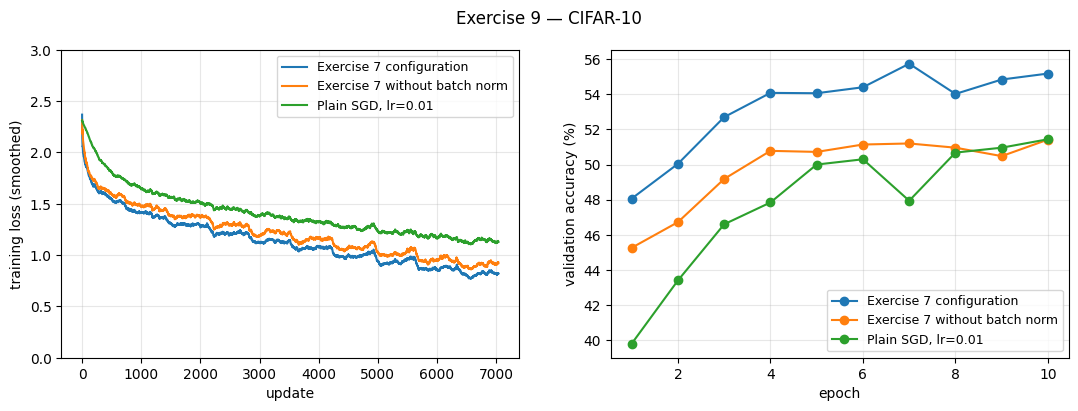

In [ ]:
# Exercise 9 (optional): CIFAR-10 with a flattened MLP.
from torchvision import datasets

cifar_train = datasets.CIFAR10(root="data", train=True, download=True)
cifar_test = datasets.CIFAR10(root="data", train=False, download=True)

cifar_images = torch.tensor(cifar_train.data, dtype=torch.float32) / 255.0
cifar_labels = torch.tensor(cifar_train.targets, dtype=torch.long)
cifar_perm = torch.randperm(50_000, generator=torch.Generator().manual_seed(42))
cifar_train_idx, cifar_val_idx = cifar_perm[:45_000], cifar_perm[45_000:]

# Calculate channel statistics using only the training partition.
train_pixels = cifar_images[cifar_train_idx]
channel_mean = train_pixels.mean(dim=(0, 1, 2))
channel_std = train_pixels.std(dim=(0, 1, 2)).clamp_min(1e-7)

def prepare_cifar(images):
    normalized = (images - channel_mean.view(1, 1, 1, 3)) / channel_std.view(1, 1, 1, 3)
    return normalized.reshape(len(images), -1)

# Keep the MNIST tensors so that Exercise 8 remains reproducible if rerun.
mnist_state = (X_train, y_train, X_val, y_val, X_test, y_test)
X_train = prepare_cifar(cifar_images[cifar_train_idx])
y_train = cifar_labels[cifar_train_idx]
X_val = prepare_cifar(cifar_images[cifar_val_idx])
y_val = cifar_labels[cifar_val_idx]

cifar_test_images = torch.tensor(cifar_test.data, dtype=torch.float32) / 255.0
X_test = prepare_cifar(cifar_test_images)
y_test = torch.tensor(cifar_test.targets, dtype=torch.long)

cifar_histories = {}
cifar_configs = [
    ("Exercise 7 configuration", BEST_CONFIG["optimizer"],
     BEST_CONFIG["learning_rate"], BEST_CONFIG["batch_size"],
     BEST_CONFIG["batch_norm"]),
    ("Exercise 7 without batch norm", BEST_CONFIG["optimizer"],
     BEST_CONFIG["learning_rate"], BEST_CONFIG["batch_size"], False),
    ("Plain SGD, lr=0.01", "SGD", 0.01, 64, False),
]

for label, optimizer_name, lr, batch_size, use_bn in cifar_configs:
    model = make_model(seed=0, n_in=3072, hidden=(512, 256), batch_norm=use_bn)
    optimizer = (optim.Adam(model.parameters(), lr=lr) if optimizer_name == "Adam"
                 else optim.SGD(model.parameters(), lr=lr))
    history = fit(model, optimizer,
                  make_loader(batch_size=batch_size, n_train=None, seed=0),
                  epochs=10)
    cifar_histories[label] = history

plot_history(cifar_histories, "Exercise 9 — CIFAR-10", ylim=(0, 3.0))

# Restore the original MNIST data used by the earlier exercises.
X_train, y_train, X_val, y_val, X_test, y_test = mnist_state

**Exercise 9: your observations and explanation.**

CIFAR-10 is more difficult than MNIST because it contains color images and more complex visual patterns. The flattened MLP loses some spatial information from the images. Compare the validation curves for the selected configuration, the same configuration without batch normalization, and plain SGD. Batch normalization may improve optimization stability, but the measured validation results determine which run performs best.